# Load preprocessed Dataset

In [10]:
import pandas as pd

file_path = '/home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/Bipolar_preprocessed.csv'
df = pd.read_csv(file_path)
df = df.copy() # defragment dataframe

display(df.head())

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,False,True,False,False,False,False,False


## Features used for clustering


In [11]:
# Features used for clustering
df_clustering = df.drop(columns=['cluster_label'], errors='ignore')

print(f"Number of features used for clustering: {df_clustering.shape[1]}")

Number of features used for clustering: 168


# Hierarchical Clustering (Agglomerative Clustering)

Now, I will perform Hierarchical Clustering using `AgglomerativeClustering`. To determine the optimal number of clusters, I will first use a dendrogram. After identifying a suitable number of clusters, I will apply the clustering algorithm.

## HIERARCHICAL: EVALUATE k = 2...10


In [12]:
# ============================================================
# HIERARCHICAL: EVALUATE k = 2...10
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd

hierarchical_results = []

for k in range(2, 11):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )

    labels = model.fit_predict(df_clustering)

    hierarchical_results.append({
        "k": k,
        "Silhouette": silhouette_score(df_clustering, labels),
        "Davies_Bouldin": davies_bouldin_score(df_clustering, labels),
        "Calinski_Harabasz": calinski_harabasz_score(
            df_clustering,
            labels
        )
    })

hierarchical_results = pd.DataFrame(hierarchical_results)

print("HIERARCHICAL CLUSTERING RESULTS")
display(hierarchical_results.round(6))

print("\nBest k according to each metric:")

print(
    "Maximum Silhouette:",
    hierarchical_results.loc[
        hierarchical_results["Silhouette"].idxmax()
    ].to_dict()
)

print(
    "Minimum Davies-Bouldin:",
    hierarchical_results.loc[
        hierarchical_results["Davies_Bouldin"].idxmin()
    ].to_dict()
)

print(
    "Maximum Calinski-Harabasz:",
    hierarchical_results.loc[
        hierarchical_results["Calinski_Harabasz"].idxmax()
    ].to_dict()
)

HIERARCHICAL CLUSTERING RESULTS


,k,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,0.364764,0.888365,123.547208
1,3,0.245421,1.645275,114.865810
2,4,0.267813,1.394553,111.896884
3,5,0.273307,1.391421,94.675948
4,6,0.280463,1.359072,80.667855
5,7,0.191549,2.171854,70.610061
6,8,0.187446,2.294634,62.567369
7,9,0.187242,2.297877,56.334016
8,10,0.188965,2.345496,51.128906



Best k according to each metric:
Maximum Silhouette: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}
Minimum Davies-Bouldin: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}
Maximum Calinski-Harabasz: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}


### Dendrogram

In [13]:
# ============================================================
# HIERARCHICAL: DENDROGRAM / MERGE DISTANCE INFORMATION
# ============================================================

from scipy.cluster.hierarchy import linkage
import pandas as pd

linked_data = linkage(
    df_clustering,
    method="ward"
)

print("Linkage matrix shape:")
print(linked_data.shape)

print("\nLast 15 merge distances:")
display(
    pd.DataFrame(
        linked_data[-15:],
        columns=[
            "cluster_1",
            "cluster_2",
            "distance",
            "cluster_size"
        ]
    ).round(6)
)

# For n=342 observations:
# 3 clusters require 342 - 3 = 339 merges.
# Therefore the merge creating the transition from 4 -> 3
# occurs at index 338 (0-based).

n_samples = len(df_clustering)

merge_index_for_3_clusters = n_samples - 3 - 1

print(
    "\nMerge distance associated with transition to 3 clusters:"
)

print(
    linked_data[merge_index_for_3_clusters, 2]
)

Linkage matrix shape:
(341, 4)

Last 15 merge distances:


,cluster_1,cluster_2,distance,cluster_size
0,643.0,665.0,7.837333,41.0
1,613.0,667.0,8.368649,40.0
2,659.0,663.0,8.393770,32.0
3,650.0,662.0,8.613841,45.0
4,658.0,668.0,8.994545,71.0
5,664.0,671.0,9.087238,77.0
6,645.0,670.0,9.092394,43.0
7,653.0,674.0,10.486735,64.0
8,661.0,675.0,11.254121,97.0
9,672.0,676.0,13.537787,168.0



Merge distance associated with transition to 3 clusters:
36.62322461954598


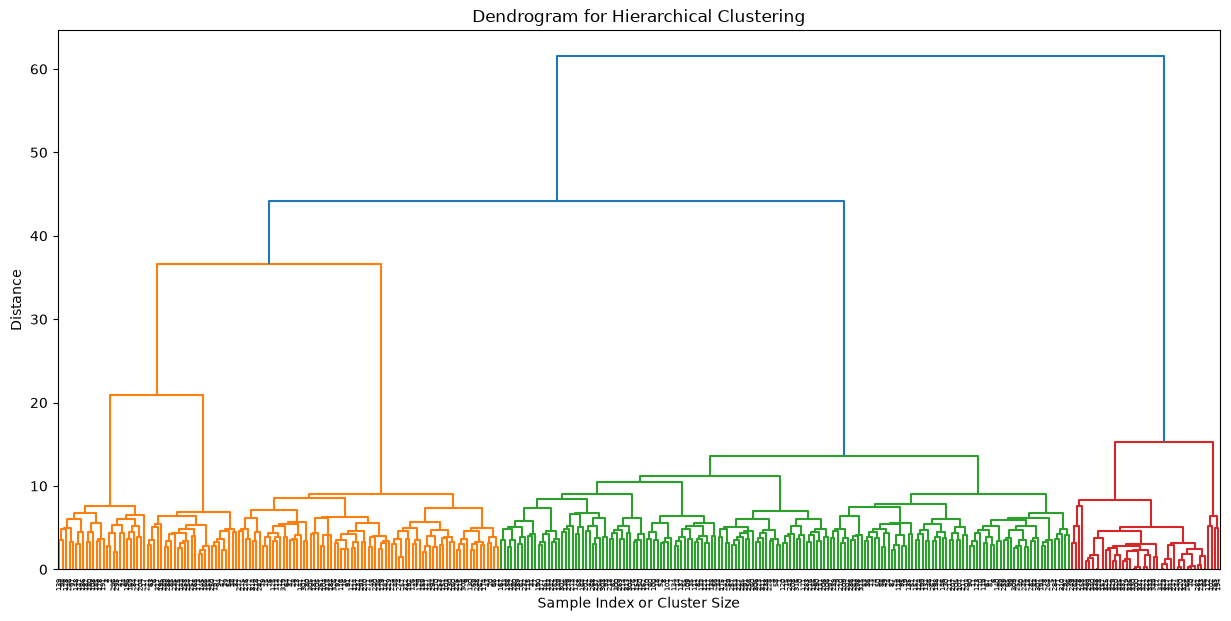

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Generate the linkage matrix
linked_data = linkage(df_clustering, method='ward') # 'ward' minimizes the variance within each cluster

# Plot the dendrogram
plt.figure(figsize=(15, 7))
dendrogram(linked_data,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
plt.show()

Based on the dendrogram, you can visually inspect for a suitable number of clusters (e.g., by looking for the longest vertical line that doesn't intersect any clusters). Let's assume an initial number of clusters, say `k=3` for demonstration, but you should adjust this based on the dendrogram. I'll add a placeholder for the number of clusters, which you can adjust later.

# Agglomerative Clustering (n_cluster=3)

In [18]:
from sklearn.cluster import AgglomerativeClustering

n_clusters = 3 # Adjust this value based on dendrogram or domain knowledge

# Apply Agglomerative Clustering
agglomerative_clustering = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
df['cluster_label'] = agglomerative_clustering.fit_predict(df_clustering)

print(f"Assigned {n_clusters} clusters to the data.")
display(df.head())

Assigned 3 clusters to the data.


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown,cluster_label
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,True,False,False,False,2
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,True,False,True,False,False,False,False,False,2
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,True,False,0
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,False,False,False,False,False,0
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,2


In [19]:
# Count the number of records in each cluster
cluster_counts = df['cluster_label'].value_counts().sort_index()
print("Number of records in each cluster:")
display(cluster_counts)

Number of records in each cluster:


cluster_label
0    130
1     44
2    168
Name: count, dtype: int64

### Cluster Evaluation Metrics

Now, I will evaluate the created clusters using three popular metrics:
1.  **Silhouette Score**: Measures how similar an object is to its own cluster compared to other clusters. Higher values indicate better-defined clusters.
2.  **Davies-Bouldin Index**: Measures the average similarity ratio of each cluster with its most similar cluster. Lower values indicate better separation between clusters.
3.  **Calinski-Harabasz Index (Variance Ratio Criterion)**: Measures the ratio of between-cluster dispersion to within-cluster dispersion. Higher values generally indicate better-defined clusters.

In [20]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Ensure there are at least 2 clusters for silhouette_score to be defined
if n_clusters > 1:
    # Calculate Silhouette Score
    silhouette = silhouette_score(df_clustering, df['cluster_label'])
    print(f"Silhouette Score: {silhouette:.3f}")

    # Calculate Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(df_clustering, df['cluster_label'])
    print(f"Davies-Bouldin Index: {davies_bouldin:.3f}")

    # Calculate Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(df_clustering, df['cluster_label'])
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.3f}")
else:
    print("Cannot compute evaluation metrics for a single cluster (n_clusters must be > 1).")

Silhouette Score: 0.245
Davies-Bouldin Index: 1.645
Calinski-Harabasz Index: 114.866


### Identifying Differentiating Features

To understand what differentiates each cluster, I will analyze the mean values of the original features within each cluster. This will help us identify which features have significantly different average values across the clusters, indicating their importance in defining the clusters.

In [22]:
import seaborn as sns

# Group by cluster and calculate the mean of each numerical feature
cluster_means = df.groupby('cluster_label')[numerical_cols].mean()
display(cluster_means)


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
cluster_label,,,,,,,,,,,,,,,,,,,,,
0,0.458052,0.385769,0.021347,0.459040,0.026847,0.055736,0.302726,0.066980,0.090637,0.017151,...,0.100000,0.246154,0.315385,0.061538,0.192308,0.000000,0.523077,0.107692,0.084615,0.0
1,0.423375,0.369930,0.012452,0.425604,0.018277,0.055824,0.271268,0.084385,0.126885,0.008790,...,0.022727,0.045455,0.909091,0.068182,0.522727,0.045455,0.181818,0.113636,0.022727,0.0
2,0.471877,0.396999,0.008694,0.463816,0.015618,0.060200,0.294480,0.104839,0.128590,0.004026,...,0.083333,0.136905,0.375000,0.089286,0.148810,0.000000,0.547619,0.130952,0.047619,0.0


In [23]:
overall_means = df[numerical_cols].mean()
print("Overall mean of each numerical feature:")
display(overall_means)

Overall mean of each numerical feature:


age                                            0.460382
age_onset                                      0.389247
total_number_of_episodes                       0.013987
total_duration_of_illness_in_months            0.457084
total_duration_of_all_episodes_in_months       0.020229
                                                 ...   
education_standard_Postgraduate                0.005848
education_standard_Primary/Secondary           0.491228
education_standard_Secondary/Pre-University    0.119883
education_standard_Undergraduate               0.058480
education_standard_Unknown                     0.000000
Length: 168, dtype: float64

In [24]:
# Calculate the difference between cluster means and overall means
mean_differences = cluster_means - overall_means
print("Difference of cluster means from overall feature means:")
display(mean_differences)

# Or, to see percentage difference (optional, might be more intuitive for some)
percentage_differences = (mean_differences / overall_means) * 100
print("Percentage difference of cluster means from overall feature means:")
display(percentage_differences)

Difference of cluster means from overall feature means:


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
cluster_label,,,,,,,,,,,,,,,,,,,,,
0,-0.002330,-0.003479,0.007360,0.001955,0.006618,-0.002204,0.008098,-0.020837,-0.023307,0.007523,...,0.018129,0.079487,-0.105668,-0.014485,-0.021143,-0.005848,0.031849,-0.012191,0.026136,0.0
1,-0.037007,-0.019317,-0.001535,-0.031480,-0.001951,-0.002116,-0.023360,-0.003431,0.012941,-0.000838,...,-0.059144,-0.121212,0.488038,-0.007842,0.309277,0.039607,-0.309410,-0.006247,-0.035752,0.0
2,0.011495,0.007751,-0.005293,0.006732,-0.004610,0.002260,-0.000148,0.017022,0.014646,-0.005602,...,0.001462,-0.029762,-0.046053,0.013262,-0.064641,-0.005848,0.056391,0.011069,-0.010860,0.0


Percentage difference of cluster means from overall feature means:


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
cluster_label,,,,,,,,,,,,,,,,,,,,,
0,-0.506109,-0.893738,52.618900,0.427783,32.717112,-3.804264,2.748591,-23.727685,-20.455103,78.136730,...,22.142857,47.692308,-25.096154,-19.053254,-9.905163,-100.000000,6.483516,-10.168856,44.692308,NaN
1,-8.038416,-4.962654,-10.977829,-6.887189,-9.645761,-3.652526,-7.928539,-3.907570,11.357311,-8.701276,...,-72.240260,-72.727273,115.909091,-10.314685,144.894147,677.272727,-62.987013,-5.210643,-61.136364,NaN
2,2.496931,1.991326,-37.841860,1.472765,-22.790543,3.900390,-0.050364,19.384120,12.853820,-58.184040,...,1.785714,-17.857143,-10.937500,17.445055,-30.283757,-100.000000,11.479592,9.233449,-18.571429,NaN


### Interpreting Cluster Characteristics

To identify if a cluster corresponds to 'manic', 'depressive', or 'normal' patterns, you should look at the `mean_differences` or `percentage_differences` DataFrames above.

*   **Manic-like Cluster**: Look for clusters where features related to mania (e.g., `total_number_of_manic_episodes`, `total_duration_of_hypomanic_episodes_in_months`, high `mania_vs_dep_first5yr` or `mania_vs_dep_recent` scores) show significantly **higher** positive differences compared to the overall mean.

*   **Depressive-like Cluster**: Look for clusters where features related to depression (e.g., `total_number_of_depressive_episodes`, high `percentage_of_time_with_symptoms` if these are predominantly depressive, or low `mania_vs_dep_first5yr` or `mania_vs_dep_recent` scores) show significantly **higher** positive differences, or where features associated with well-being/euthymia (`rate_time_spent_euthymic_since_onset`) show significantly **lower** negative differences.

*   **Normal/Euthymic Cluster**: Look for clusters that show **smaller differences** (closer to zero) across most features, or particularly **higher** positive differences in features indicating stability or well-being (e.g., `rate_time_spent_euthymic_since_onset`, `insightinterepisode`, `occupational_func_5yr`).

**Example Interpretation Steps:**

1.  **Examine `cluster_means` and `mean_differences`:** Look at the actual mean values for each feature within each cluster, and how they deviate from the overall average.
2.  **Focus on Key Features:** Prioritize features that are most relevant to the definitions of manic, depressive, and normal states based on your domain knowledge of Bipolar Disorder (e.g., episode counts, duration, insight, functional scores).
3.  **Identify Extremes:** Clusters with very high or very low values for these key features are more likely to represent distinct groups.
4.  **Consider all features together:** A cluster isn't defined by just one feature, but by a combination of high and low values across multiple distinguishing features.

### Interpreting Hierarchical Clusters

Based on the `mean_differences` and `percentage_differences` relative to the overall population means, here's an interpretation of the three clusters identified by hierarchical clustering:

*   **Cluster 0 (Frequent & Severe Episodes / Depressive-leaning):**
    *   **High positive differences** in: `total_number_of_episodes` (very high), `total_duration_of_all_episodes_in_months`, `total_number_of_manic_episodes`, `total_number_of_depressive_episodes` (extremely high), `insightinterepisode`, `occupational_func_5yr`, `number_of_ip_care_recieved`.
    *   **Characteristics:** This cluster is characterized by a significantly higher frequency and duration of both manic and depressive episodes, with a particularly pronounced increase in depressive episodes. The high number of inpatient care received suggests higher illness severity or complexity. High insight and occupational functioning, despite frequent episodes, might indicate a subgroup that is actively managing their condition or has developed coping strategies over time.

*   **Cluster 1 (Mixed/Hypomanic Predominant with Complex Course):**
    *   **High positive differences** in: `age_onset`, `total_number_of_hypomanic_episodes`, `total_number_of_mixed_episodes` (very high), `rate_prominence_of_mixed_episodes` (very high), `number_of_ip_care_recieved` (very high).
    *   **High negative differences** in: `total_number_of_episodes`, `total_duration_of_all_episodes_in_months`, `total_number_of_depressive_episodes`, `mania_vs_dep_first5yr`, `mania_vs_dep_recent`, `insightinterepisode`, `occupational_func_5yr`.
    *   **Characteristics:** This cluster stands out due to a significantly higher number and prominence of mixed episodes and hypomanic episodes, despite lower overall episode counts for pure manic or depressive states. The very high `number_of_ip_care_recieved` suggests that the complexity of mixed features or specific symptom profiles necessitates frequent clinical intervention. Lower scores in `mania_vs_dep` suggest a more depressive presentation within their mixed states, or that their manic features are predominantly hypomanic rather than full-blown mania. They also tend to have lower insight and occupational functioning compared to the overall mean.

*   **Cluster 2 (Less Severe / Euthymic-leaning / Good Prognosis):**
    *   **High positive differences** in: `rate_time_spent_euthymic_since_onset`, `mania_vs_dep_first5yr`, `mania_vs_dep_recent`, `rate_response_to_lithium_treatment`.
    *   **High negative differences** in: `age`, `age_onset`, `total_number_of_episodes`, `total_duration_of_illness_in_months`, `total_duration_of_all_episodes_in_months`, `total_number_of_depressive_episodes`, `total_number_of_hypomanic_episodes`, `number_of_ip_care_recieved`, `occupational_func_5yr`.
    *   **Characteristics:** This cluster represents individuals with a generally less severe course of illness. They exhibit significantly fewer total episodes (both manic and depressive), shorter illness and episode durations, and spend a higher proportion of their time in a euthymic (stable) state. Their lower number of inpatient care received and better response to lithium treatment suggest a more manageable condition and a relatively good prognosis. While occupational functioning is lower than the mean, the overall picture indicates better stability compared to the other clusters.